**Notebook Criado por:** MSc. Eng. Paulo Silva  
**Notebook Criado em:** 12 / 11 / 2026  
**Última Atualização:** 17 / 11 / 2026  

**Obs:** Este notebook foi desenvolvido sob auxílio de ferramentas de IA.

# **Aula 08 — Problema 2D direto com DeepXDE**

## Equação de Laplace para a condução de calor

Neste notebook vamos resolver um problema bidimensional estacionário de condução de calor usando uma PINN.

Serão comparadas duas situações:

1. treinamento usando somente a equação e as condições de contorno;
2. treinamento usando também dados sintéticos gerados pela solução analítica.

A solução analítica será calculada com **50 termos da série**. Ela será usada para validar os resultados e gerar as observações do segundo caso.


## **1. Formulação matemática**

Consideramos a equação de Laplace para a temperatura adimensional $\theta(x,y)$:

$$
\frac{\partial^2\theta}{\partial x^2}
+\frac{\partial^2\theta}{\partial y^2}=0,
\qquad 0< x < L, \qquad 0 < y < H.
$$

A temperatura adimensional é definida por

$$
\theta=\frac{T-T_1}{T_2-T_1}.
$$

As três faces inferiores estão em $T_1$, enquanto a face superior está em $T_2$:

$$
\theta(0,y)=0,
\qquad
\theta(L,y)=0,
\qquad
\theta(x,0)=0,
$$

$$
\theta(x,H)=1.
$$

A solução analítica por separação de variáveis é

$$
\theta(x,y)=
\frac{2}{\pi}
\sum_{n=1}^{N}
\frac{1-(-1)^n}{n}
\sin\left(\frac{n\pi x}{L}\right)
\frac{\sinh\left(\frac{n\pi y}{L}\right)}
{\sinh\left(\frac{n\pi H}{L}\right)}.
$$

Neste notebook, $N=50$. A temperatura dimensional é recuperada por

$$
T=T_1+(T_2-T_1)\theta.
$$

**Observação:** nos dois cantos superiores existe uma incompatibilidade idealizada entre as faces laterais e a face superior. Por isso, erros maiores próximos aos cantos são esperados.


## **2. Ambiente computacional**

O backend será definido como PyTorch antes da importação do DeepXDE. Se necessário no Google Colab, retire o comentário da instalação na célula abaixo.


In [ ]:
# !pip -q install deepxde torch
!pip -q install deepxde torch

In [ ]:
import os

# O backend precisa ser definido antes de importar o DeepXDE.
os.environ["DDE_BACKEND"] = "pytorch"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import deepxde as dde
import matplotlib.pyplot as plt
import numpy as np

dde.config.set_default_float("float64")
dde.config.set_random_seed(1234)

print("Backend utilizado:", dde.backend.backend_name)

Set the default float type to float64
Backend utilizado: pytorch


## **3. Parâmetros do problema e solução analítica**

A PINN será treinada para a temperatura adimensional. A conversão para Kelvin será feita apenas na etapa de visualização.


In [ ]:
# Geometria e temperaturas de referência
L = 1.0
H = 1.0
T1 = 300.0  # [K]
T2 = 500.0  # [K]

# Número de termos utilizado na solução analítica e nos dados sintéticos
N_TERMS = 50

# Configuração do treinamento
ITERATIONS = 5000
NUM_DOMAIN = 800     #Pontos de Colocação no Dominio Interno
NUM_BOUNDARY = 160   #Pontos no Contorno
NUM_TEST = 1600      #Pontos para acompanhar o desempenho (não ajudam no treino)

def theta_analitica(X, n_terms=N_TERMS):
    '''Solução analítica adimensional com n_terms termos.'''
    X = np.asarray(X)
    x = X[:, 0:1]
    y = X[:, 1:2]

    theta = np.zeros_like(x, dtype=float)

    for n in range(1, n_terms + 1):
        coeficiente = (2.0 / np.pi) * (1.0 - (-1.0) ** n) / n
        theta += (
            coeficiente
            * np.sin(n * np.pi * x / L)
            * np.sinh(n * np.pi * y / L)
            / np.sinh(n * np.pi * H / L)
        )

    return theta

def temperatura_analitica(X, n_terms=N_TERMS):
    return T1 + (T2 - T1) * theta_analitica(X, n_terms)


In [ ]:
# Malha regular utilizada somente para avaliação e visualização
x_eval = np.linspace(0.0, L, 121)
y_eval = np.linspace(0.0, H, 121)
X_grid, Y_grid = np.meshgrid(x_eval, y_eval, indexing="ij")
X_eval = np.column_stack((X_grid.ravel(), Y_grid.ravel()))

theta_ref = theta_analitica(X_eval).reshape(X_grid.shape)
T_ref = temperatura_analitica(X_eval).reshape(X_grid.shape)

print(f"Solução analítica calculada com N = {N_TERMS} termos.")


Solução analítica calculada com N = 50 termos.


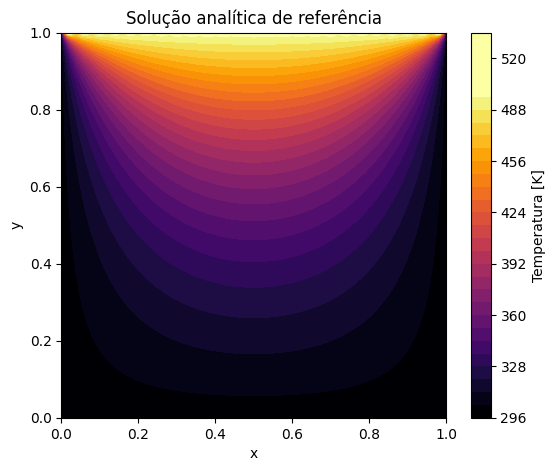

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))

mapa = ax.contourf(X_grid, Y_grid, T_ref,
    levels=30, cmap="inferno", vmin=T1, vmax=T2,)

ax.set_title("Solução analítica de referência")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
fig.colorbar(mapa, ax=ax, label="Temperatura [K]")
plt.show()


## **4. Geometria, equação e condições de contorno**

A rede produzirá $\theta_\vartheta(x,y)$. O resíduo físico é

$$
r_\vartheta(x,y)=
\frac{\partial^2\theta_\vartheta}{\partial x^2} +
\frac{\partial^2\theta_\vartheta}{\partial y^2}.
$$

Durante o treinamento, a PINN será ajustada para que esse resíduo seja próximo de zero e para que as condições de contorno sejam satisfeitas.

$$
\theta(0,y)=0, \qquad \theta(L,y)=0, \qquad
\theta(x,0)=0, \qquad \theta(x,H)=1.
$$


In [ ]:
# GEOMETRIA DO PROBLEMA
geom = dde.geometry.Rectangle([0.0, 0.0], [L, H])

# EQUACAO DIFERENCIAL PARA A PINN
def pde(x, y):
    theta_xx = dde.grad.hessian(y, x, i=0, j=0)
    theta_yy = dde.grad.hessian(y, x, i=1, j=1)
    return theta_xx + theta_yy

# DEFININDO A POSICAO DAS CONDICOES DE CONTORNO
def boundary_left(x, on_boundary):
    return (on_boundary and np.isclose(x[0], 0.0) and not np.isclose(x[1], H))

def boundary_right(x, on_boundary):
    return (on_boundary and np.isclose(x[0], L) and not np.isclose(x[1], H))

def boundary_bottom(x, on_boundary):
    return (on_boundary and np.isclose(x[1], 0.0))

def boundary_top(x, on_boundary):
    return (on_boundary and np.isclose(x[1], H)
        and not np.isclose(x[0], 0.0) and not np.isclose(x[0], L))

# DEFININDO OS VALORES PARA O CONTORNO
def valor_zero(x):
    return np.zeros((len(x), 1))

def valor_um(x):
    return np.ones((len(x), 1))

# JUNTANDO AS CONDICOES E OS VALORES PARA USO DA BIBLIOTECA
bc_left = dde.icbc.DirichletBC(geom, valor_zero, boundary_left)
bc_right = dde.icbc.DirichletBC(geom, valor_zero, boundary_right)
bc_bottom = dde.icbc.DirichletBC(geom, valor_zero, boundary_bottom)
bc_top = dde.icbc.DirichletBC(geom, valor_um, boundary_top)
bcs_base = [bc_left, bc_right, bc_bottom, bc_top]


## **5. Dados sintéticos para o segundo treinamento**

Os dados são gerados pela solução analítica com os mesmos 50 termos definidos anteriormente. Eles representam medições de temperatura em pontos internos da placa.

Esses pontos não são utilizados no caso sem dados. No caso com dados, eles entram como uma parcela adicional da função de perda.


In [ ]:
# Pontos internos de observação, afastados das fronteiras
n_obs_por_direcao = 10
x_obs = np.linspace(0.1 * L, 0.9 * L, n_obs_por_direcao)
y_obs = np.linspace(0.1 * H, 0.9 * H, n_obs_por_direcao)
X_obs_grid, Y_obs_grid = np.meshgrid(x_obs,y_obs,indexing="ij",)
X_obs = np.column_stack((X_obs_grid.ravel(), Y_obs_grid.ravel()))
y_obs = theta_analitica(X_obs, N_TERMS)   # Dados Sinteticos

print(f"Quantidade de observações internas: {len(X_obs)}")


Quantidade de observações internas: 100


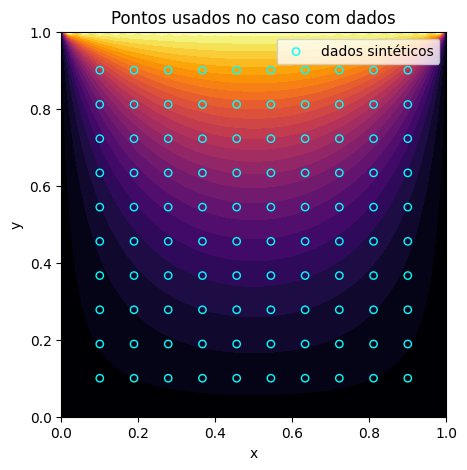

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.contourf(X_grid, Y_grid, T_ref,
    levels=30, cmap="inferno", vmin=T1, vmax=T2,)

ax.scatter(X_obs[:, 0], X_obs[:, 1], s=28, facecolors="none", edgecolors="cyan",
    label="dados sintéticos",)

ax.set_title("Pontos usados no caso com dados")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
ax.legend()
plt.show()

## **6. Função de treinamento**

A função abaixo cria um modelo novo para cada experimento. Assim, os casos sem dados e com dados começam com uma rede independente.

A única diferença entre os dois treinamentos é a presença de `PointSetBC` com as observações internas.

O `PointSetBC` adiciona à função de perda o termo
$$
\mathcal{L}_{\mathrm{dados}} =
\frac{1}{N} \sum_{j=1}^{N}
\left[T_{\mathrm{PINN}}(x_j)-T_j^{\mathrm{obs}}
\right]^2.
$$

In [ ]:
def criar_modelo(usando_dados, seed=1234):
    dde.config.set_random_seed(seed)

    bcs = list(bcs_base) # Condensando as BCs em uma lista

    # Informando os dados sinteticos para a biblioteca
    if usando_dados:
        bc_dados = dde.icbc.PointSetBC(X_obs, y_obs, component=0,)
        bcs.append(bc_dados)

    # Concatenando as informacoes
    data = dde.data.PDE(
        geom,
        pde,
        bcs,
        num_domain=NUM_DOMAIN,
        num_boundary=NUM_BOUNDARY,
        num_test=NUM_TEST,
    )

    # Montando a rede neural, funcao de ativacao e valores iniciais
    net = dde.nn.FNN([2] + [20] * 3 + [1], "tanh", "Glorot uniform",)
    model = dde.Model(data, net)
    model.compile("adam",lr=1e-3,)
    return model


def treinar(usando_dados, seed=1234):
    nome = "com dados" if usando_dados else "sem dados"
    print(f"\nTreinamento: {nome}")

    model = criar_modelo(usando_dados, seed=seed)

    inicio = time.perf_counter()
    losshistory, train_state = model.train(
        iterations=ITERATIONS,
        display_every=500,
        verbose=1,
    )
    tempo = time.perf_counter() - inicio

    return {
        "modelo": model,
        "losshistory": losshistory,
        "train_state": train_state,
        "tempo": tempo,
    }


## **7. Treinamento sem dados e com dados**

Os dois modelos utilizam apenas o otimizador Adam, com 500 iterações. A solução analítica não participa do treinamento sem dados; ela será usada posteriormente para avaliar os resultados.


In [ ]:
resultados = {
    "sem dados": treinar(usando_dados=False, seed=1234),
    "com dados": treinar(usando_dados=True, seed=1234),
}



Treinamento: sem dados
Compiling model...
'compile' took 0.000169 s

Training model...

Step      Train loss                                            Test loss                                             Test metric
0         [1.64e-02, 3.22e-03, 1.49e-01, 3.86e-02, 1.60e+00]    [1.55e-02, 3.22e-03, 1.49e-01, 3.86e-02, 1.60e+00]    []  
500       [2.67e-02, 7.48e-02, 8.37e-02, 5.89e-03, 9.84e-02]    [1.93e-02, 7.48e-02, 8.37e-02, 5.89e-03, 9.84e-02]    []  
1000      [6.36e-03, 3.49e-02, 4.74e-02, 6.68e-03, 3.39e-02]    [4.18e-03, 3.49e-02, 4.74e-02, 6.68e-03, 3.39e-02]    []  
1500      [2.59e-03, 1.44e-02, 2.44e-02, 1.38e-03, 4.42e-02]    [1.57e-03, 1.44e-02, 2.44e-02, 1.38e-03, 4.42e-02]    []  
2000      [1.57e-03, 1.08e-02, 2.00e-02, 3.25e-04, 4.71e-02]    [1.08e-03, 1.08e-02, 2.00e-02, 3.25e-04, 4.71e-02]    []  
2500      [1.40e-03, 1.07e-02, 1.90e-02, 2.73e-04, 4.55e-02]    [9.42e-04, 1.07e-02, 1.90e-02, 2.73e-04, 4.55e-02]    []  
3000      [1.13e-03, 1.10e-02, 1.84e-02, 3.

## **8. Métricas de erro e tempo**

A comparação será feita na mesma malha regular para os dois modelos.


In [ ]:
def avaliar(resultado):
    modelo = resultado["modelo"]
    theta_pred = modelo.predict(X_eval).reshape(X_grid.shape)
    T_pred = T1 + (T2 - T1) * theta_pred
    erro_abs = np.abs(T_ref - T_pred)

    loss_train = np.asarray(
        resultado["losshistory"].loss_train,
        dtype=float,
    )
    perda_final = np.sum(loss_train[-1])

    erro_l2 = dde.metrics.l2_relative_error(
        T_ref.reshape(-1, 1),
        T_pred.reshape(-1, 1),
    )

    return {
        "T_pred": T_pred,
        "erro_abs": erro_abs,
        "perda_final": perda_final,
        "erro_l2": erro_l2,
        "erro_max": np.max(erro_abs),
    }


for nome, resultado in resultados.items():
    resultado.update(avaliar(resultado))

    print(f"\nCaso: {nome}")
    print(f"Tempo de treinamento: {resultado['tempo']:.2f} s")
    print(f"Perda final: {resultado['perda_final']:.4e}")
    print(f"Erro relativo L2: {resultado['erro_l2']:.4e}")
    print(f"Erro absoluto máximo: {resultado['erro_max']:.4e} K")



Caso: sem dados
Tempo de treinamento: 44.01 s
Perda final: 6.1436e-02
Erro relativo L2: 2.2892e-02
Erro absoluto máximo: 1.2914e+02 K

Caso: com dados
Tempo de treinamento: 44.85 s
Perda final: 6.6793e-02
Erro relativo L2: 2.4234e-02
Erro absoluto máximo: 1.3246e+02 K


## **9. Curvas de convergência**

A perda total é calculada somando as parcelas registradas pelo DeepXDE. O eixo vertical usa escala logarítmica para facilitar a visualização da redução do erro.


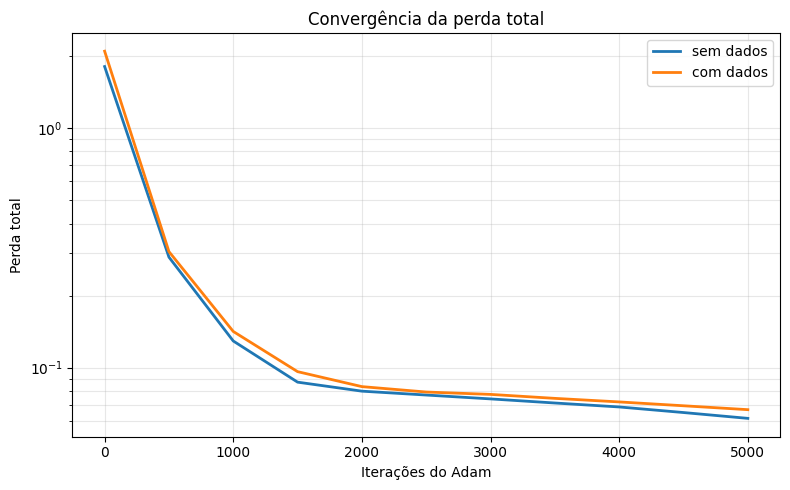

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for nome, resultado in resultados.items():
    history = resultado["losshistory"]
    steps = np.asarray(history.steps)
    loss_train = np.asarray(history.loss_train, dtype=float)
    loss_total = np.sum(loss_train, axis=1)

    ax.semilogy(
        steps,
        loss_total,
        linewidth=2,
        label=nome,
    )

ax.set_title("Convergência da perda total")
ax.set_xlabel("Iterações do Adam")
ax.set_ylabel("Perda total")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## **10. Solução analítica, PINN e erro absoluto**

Os mapas abaixo mostram a temperatura dimensional. A solução analítica é a mesma utilizada para gerar os dados sintéticos do caso com dados.


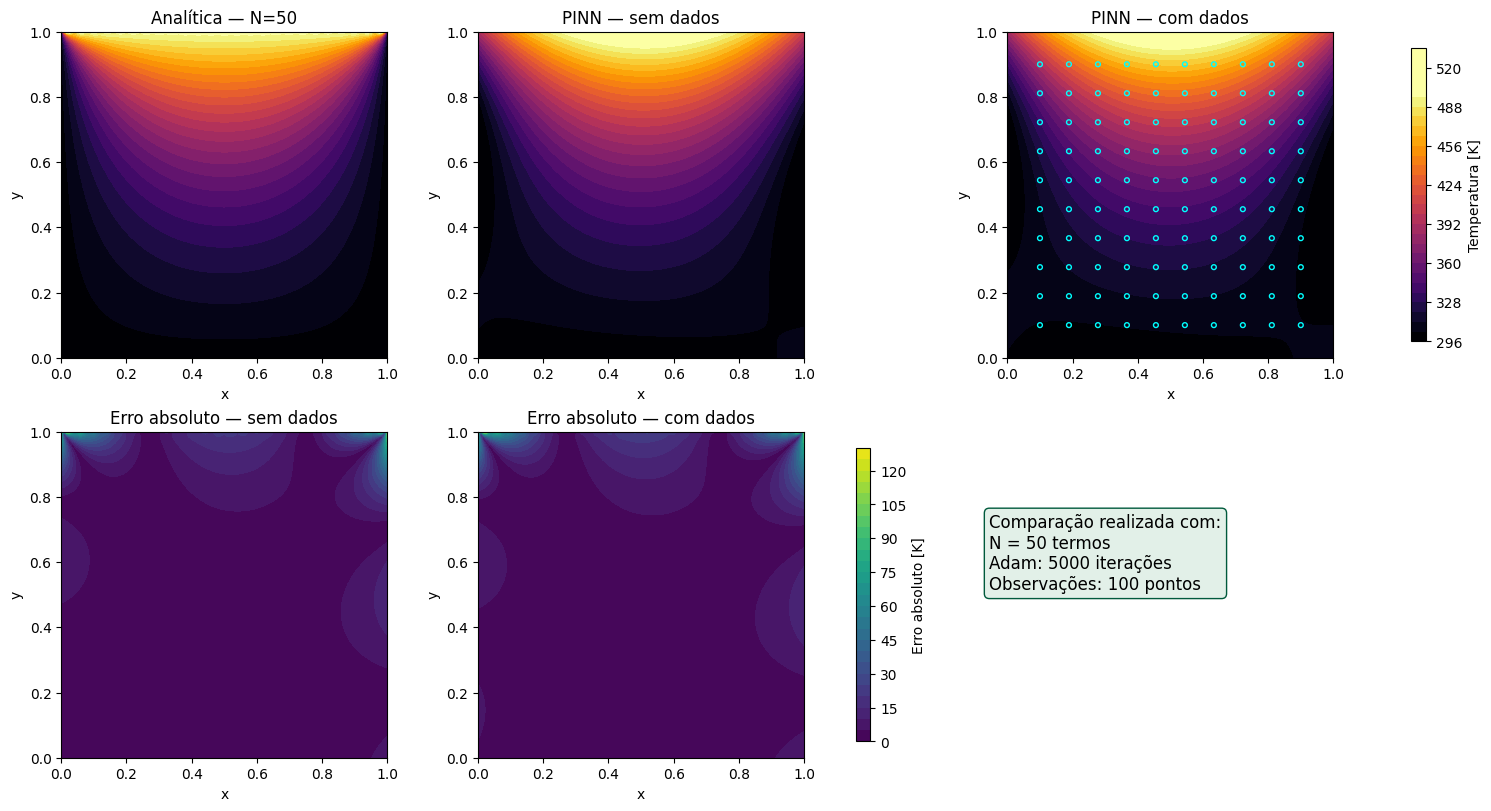

In [ ]:
vmin = min(T_ref.min(), *(r["T_pred"].min() for r in resultados.values()))
vmax = max(T_ref.max(), *(r["T_pred"].max() for r in resultados.values()))
erro_vmax = max(r["erro_abs"].max() for r in resultados.values())

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True,)

mapa_ref = axes[0, 0].contourf(
    X_grid, Y_grid, T_ref,
    levels=30, cmap="inferno", vmin=T1, vmax=T2,
)
axes[0, 0].set_title("Analítica — N=50")

mapa_sem = axes[0, 1].contourf(
    X_grid, Y_grid, resultados["sem dados"]["T_pred"],
    levels=30, cmap="inferno", vmin=T1, vmax=T2,
)
axes[0, 1].set_title("PINN — sem dados")

mapa_com = axes[0, 2].contourf(
    X_grid, Y_grid, resultados["com dados"]["T_pred"],
    levels=30, cmap="inferno", vmin=T1, vmax=T2,
)
axes[0, 2].scatter(
    X_obs[:, 0], X_obs[:, 1],
    s=12, facecolors="none", edgecolors="cyan",
)
axes[0, 2].set_title("PINN — com dados")

erro_sem = axes[1, 0].contourf(
    X_grid, Y_grid, resultados["sem dados"]["erro_abs"],
    levels=30, cmap="viridis", vmin=0, vmax=erro_vmax,
)
axes[1, 0].set_title("Erro absoluto — sem dados")

erro_com = axes[1, 1].contourf(
    X_grid, Y_grid, resultados["com dados"]["erro_abs"],
    levels=30, cmap="viridis", vmin=0, vmax=erro_vmax,
)
axes[1, 1].set_title("Erro absoluto — com dados")

axes[1, 2].axis("off")
axes[1, 2].text(
    0.05,
    0.75,
    "Comparação realizada com:\n"
    f"N = {N_TERMS} termos\n"
    f"Adam: {ITERATIONS} iterações\n"
    f"Observações: {len(X_obs)} pontos",
    transform=axes[1, 2].transAxes,
    fontsize=12,
    va="top",
    bbox=dict(
        boxstyle="round",
        facecolor="#E2F0E8",
        edgecolor="#005A3C",
    ),
)

for ax in axes.flat:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

fig.colorbar(mapa_ref, ax=axes[0, :], label="Temperatura [K]", shrink=0.9,)
fig.colorbar(erro_sem, ax=axes[1, :2],label="Erro absoluto [K]",shrink=0.9,)

plt.show()


## 11. Interpretação

- No caso **sem dados**, a PINN aprende a satisfazer a equação de Laplace e as condições de contorno.
- No caso **com dados**, as observações internas acrescentam restrições à função de perda.
- Os dados sintéticos foram gerados com a solução analítica de 50 termos.
- A solução analítica não é necessária para treinar o caso sem dados; ela foi usada apenas para gerar dados e medir erros.
- Como o treinamento usa apenas 5000 iterações de Adam, os resultados representam uma demonstração didática, não necessariamente a convergência final do problema.
- Erros maiores próximos aos cantos superiores são esperados devido à incompatibilidade idealizada entre as condições de contorno.

A ideia principal é:

> A PINN pode resolver o problema usando apenas a física, mas dados internos podem fornecer restrições adicionais e alterar a qualidade da aproximação.
